# Nested sampling and Bayesian evidence

Nested sampling computes the **Bayesian evidence** (marginal likelihood)

$$\mathcal{Z} = \int \mathcal{L}(\theta)\, \pi(\theta)\, d\theta$$

and produces posterior samples as a by-product. The evidence is what MCMC does not give
you: it is the quantity needed to compare models.

This notebook uses `psiphy.mcmc.NestedSampler` with the
[nautilus](https://nautilus-sampler.readthedocs.io) backend, which needs few likelihood
calls (useful for expensive likelihoods) and can evaluate likelihoods in batches.
The [dynesty](https://dynesty.readthedocs.io) backend is a drop-in alternative if it is
installed; the interface and the result format are identical:

```python
NestedSampler(log_likelihood, prior, backend="dynesty")   # instead of "nautilus"
```

Contents:
1. Checking the evidence against an analytic value
2. Posterior samples and getdist export
3. Model comparison with Bayes factors

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from getdist import plots

from psiphy.mcmc import NestedSampler
from psiphy.utils.prior import UniformPrior
from psiphy.toy_models import NoisyLine

np.random.seed(1)

---
## 1  Evidence of a Gaussian likelihood in a box

Take a normalised 2-D Gaussian likelihood and a uniform prior on a box much wider than the
Gaussian. The integral of the likelihood is 1, and the prior density is $1/V$, so
$\mathcal{Z} = 1/V$ exactly.

In [2]:
mean = np.array([0.5, -1.0])
cov = np.array([[1.0, 0.3], [0.3, 0.5]])
icov = np.linalg.inv(cov)
norm = -0.5 * np.log(np.linalg.det(2 * np.pi * cov))

def log_like_gauss(theta):
    d = theta - mean
    return norm - 0.5 * d @ icov @ d

box = UniformPrior({'x': (-10, 10), 'y': (-10, 10)})
ns = NestedSampler(log_like_gauss, box, backend='nautilus', n_live=500, seed=0)
res = ns.run(dlogz=0.01).get_result()

print(f"log Z (nautilus) = {res['log_evidence']:.3f}")
print(f"log Z (analytic) = {np.log(1 / 400):.3f}")
print(f"effective sample size = {res['ess']:.0f}")

log Z (nautilus) = -5.988
log Z (analytic) = -5.991
effective sample size = 10066


`get_result()` returns the same keys for every backend:

| Key | Content |
|---|---|
| `log_evidence`, `log_evidence_err` | $\log\mathcal{Z}$ and its error (`None` for nautilus) |
| `samples`, `weights` | weighted posterior samples (weights aligned with samples) |
| `equal_weight_samples` | resampled, unweighted draws |
| `log_likelihood`, `ess`, `backend` | per-sample log-likelihood, effective sample size, backend name |

---
## 2  Posterior: fitting a noisy line

The likelihood function takes only `theta`; the data are captured in a closure. The prior
object supplies the unit-cube transform and the parameter names.

In [3]:
line = NoisyLine(Nx=40, noise_sigma=0.8)
theta_true = np.array([-0.8, 5.0])
y_obs = line.simulate(theta_true)

prior_line = UniformPrior({'m': (-3, 3), 'b': (0, 10)})
ns_line = NestedSampler(lambda t: line.log_prob(t, y_obs), prior_line, backend='nautilus', seed=0)
res_line = ns_line.run().get_result()

post_mean = np.average(res_line['samples'], weights=res_line['weights'], axis=0)
print('posterior mean:', post_mean.round(3), '  truth:', theta_true)
print(f"log Z = {res_line['log_evidence']:.2f}")

posterior mean: [-0.793  4.893]   truth: [-0.8  5. ]
log Z = -53.90


Removed no burn in


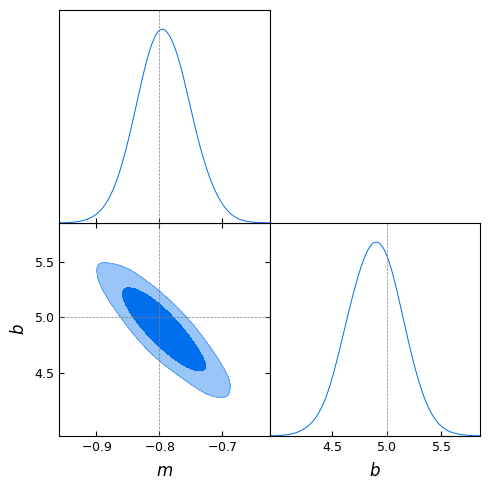

In [4]:
mc = ns_line.to_getdist(labels=['m', 'b'], label='nautilus')
g = plots.get_subplot_plotter(width_inch=5)
g.triangle_plot(mc, filled=True, markers={'m': theta_true[0], 'b': theta_true[1]})
plt.show()

---
## 3  Model comparison: is there curvature?

Compare a straight line ($M_1$: $y = m x + b$) with a quadratic
($M_2$: $y = a x^2 + m x + b$). The **Bayes factor**

$$\ln B_{21} = \ln \mathcal{Z}_2 - \ln \mathcal{Z}_1$$

weighs goodness of fit against model complexity: the extra parameter $a$ spreads prior
mass over values the data don't support, which is penalised (Occam's razor).
A rough guide (Jeffreys/Kass–Raftery): $|\ln B| < 1$ inconclusive, $1$–$3$ positive,
$3$–$5$ strong, $>5$ very strong.

We test two data sets: one generated from a straight line and one with mild curvature.

In [5]:
x = line.x
sigma = line.noise_sigma

def make_loglike(y, model):
    def loglike(t):
        mu = model(t)
        return -0.5 * np.sum((y - mu) ** 2) / sigma**2 - 0.5 * len(y) * np.log(2 * np.pi * sigma**2)
    return loglike

linear = lambda t: t[0] * x + t[1]
quadratic = lambda t: t[0] * x**2 + t[1] * x + t[2]

prior_M1 = UniformPrior({'m': (-3, 3), 'b': (0, 10)})
prior_M2 = UniformPrior({'a': (-0.3, 0.3), 'm': (-3, 3), 'b': (0, 10)})

datasets = {
    'straight line (a = 0)':  -0.8 * x + 5.0 + np.random.normal(0, sigma, x.size),
    'curved (a = 0.08)':      0.08 * x**2 - 0.8 * x + 5.0 + np.random.normal(0, sigma, x.size),
}

rows = []
for name, y in datasets.items():
    r1 = NestedSampler(make_loglike(y, linear), prior_M1, backend='nautilus', seed=0).run().get_result()
    r2 = NestedSampler(make_loglike(y, quadratic), prior_M2, backend='nautilus', seed=0).run().get_result()
    rows.append((name, r1['log_evidence'], r2['log_evidence'], r2))

print(f"{'data':24s} {'ln Z (line)':>12s} {'ln Z (quad)':>12s} {'ln B_21':>9s}")
for name, z1, z2, _ in rows:
    print(f"{name:24s} {z1:12.2f} {z2:12.2f} {z2 - z1:9.2f}")

data                      ln Z (line)  ln Z (quad)   ln B_21
straight line (a = 0)          -52.46       -54.83     -2.37
curved (a = 0.08)              -55.96       -47.58      8.37


For straight-line data the Bayes factor favours the simpler model even though the
quadratic fits at least as well; for curved data the quadratic wins clearly. The posterior
on the curvature parameter shows why:

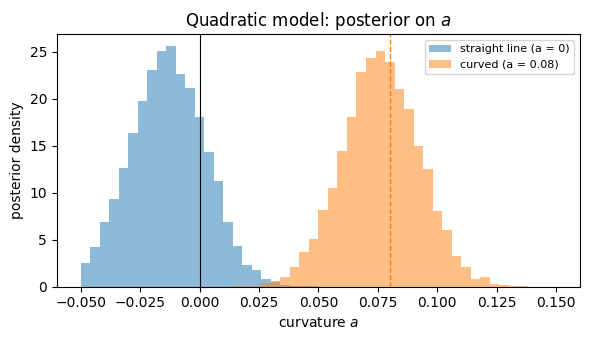

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for (name, _, _, r2), c in zip(rows, ['C0', 'C1']):
    ax.hist(r2['samples'][:, 0], weights=r2['weights'], bins=50, range=(-0.05, 0.15),
            density=True, alpha=0.5, color=c, label=name)
ax.axvline(0, c='k', lw=0.8)
ax.axvline(0.08, c='C1', ls='--', lw=1)
ax.set(xlabel='curvature $a$', ylabel='posterior density', title='Quadratic model: posterior on $a$')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Summary

| Task | Code |
|---|---|
| Run | `NestedSampler(log_likelihood, prior, backend='nautilus').run(dlogz=...)` |
| Results | `get_result()` → `log_evidence`, `samples`, `weights`, `equal_weight_samples`, ... |
| Plot | `to_getdist()` → getdist `MCSamples` |
| Compare models | $\ln B_{21} = \ln\mathcal{Z}_2 - \ln\mathcal{Z}_1$ |
| Other backend | `backend='dynesty'` (also gives `log_evidence_err`) |

The likelihood must be **normalised** (include constants such as
$-\tfrac12 N \ln 2\pi\sigma^2$) when evidences of models with different data
normalisations are compared; constants common to all models cancel in the Bayes factor.

Parallel evaluation: pass `pool=`. Batched / GPU likelihoods are planned (issue #20).